# 01 - EDA and profitability

Story notebook. All logic lives in `src/sca/eda.py` and `src/sca/profitability.py`; this notebook calls it and shows the results. Run `python -m sca ingest` first. Numbers here match `reports/eda_findings.md`.

In [1]:
import json

from IPython.display import Image, Markdown, display

from sca import eda
from sca.config import PROJECT_ROOT
from sca.ingest import read_processed

PROC = PROJECT_ROOT / "data" / "processed"
FIG = PROJECT_ROOT / "reports" / "figures"
tables = read_processed(PROC)
df = eda.build_frame(tables)
cutoff = json.loads((PROC / "meta.json").read_text())["tail"].get("last_normal_date")
print(f"{len(df):,} order items, forecasting cutoff {cutoff}")

180,519 order items, forecasting cutoff 2017-10-01


## Run every analysis

Each finding carries its numbers, chart and a so-what.

In [2]:
findings, model = eda.run_all(df, cutoff, FIG)
len(findings)

6

### Finding 1: Demand is steady at about 10,884 units a month, with a seasonal swing of 10%

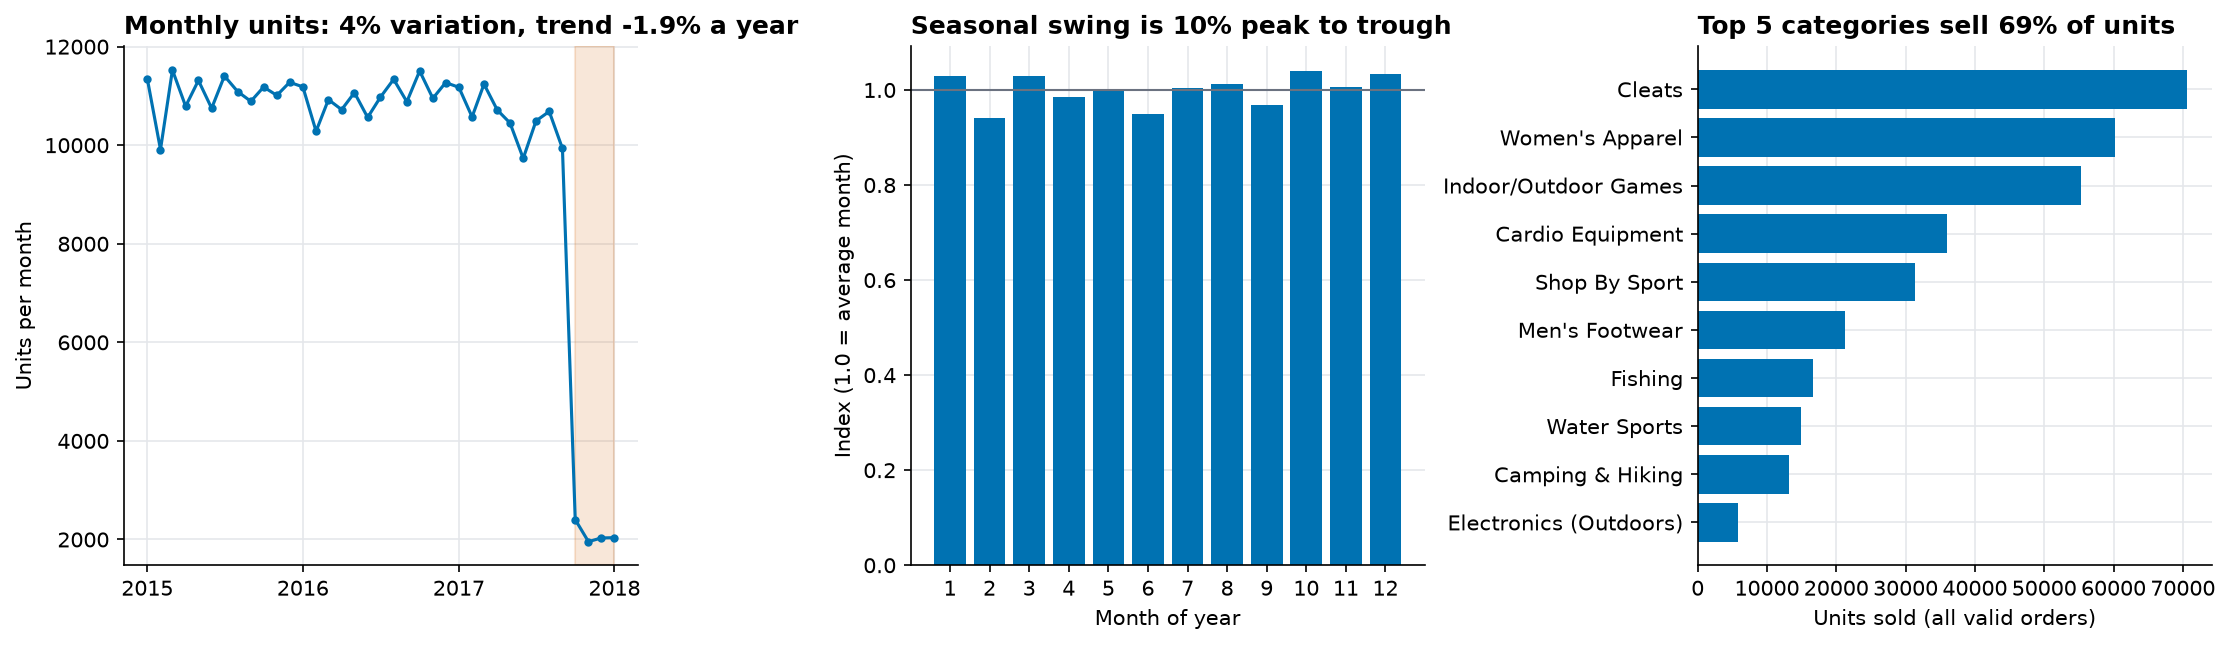

- Average full month: 10,884 units (coefficient of variation 4.2%) across 33 complete months before the cutoff.
- Linear trend across those months: -1.9% a year.
- Month-of-year index runs from 0.94 (February) to 1.04 (October).
- Top 5 categories account for 68.9% of units; 8 of 51 categories cover 80%.
- After the cutoff (2017-10-01), the 4 later months average 2,107 units, 81% below the earlier months; they are excluded from forecasting.

**So what:** There is little trend or seasonality to exploit, so beating a seasonal-naive baseline will be hard and may be a small margin. With 8 categories covering 80% of units, forecasting effort should go there.

In [3]:
f = findings[0]
display(Markdown(f"### Finding {f.number}: {f.headline}"))
display(Image(FIG / f.figure))
display(Markdown(chr(10).join(f"- {e}" for e in f.evidence)))
display(Markdown(f"**So what:** {f.so_what}"))

### Finding 2: Shipping mode drives lateness (40% to 100% late); region moves it by at most 13 pp within a mode

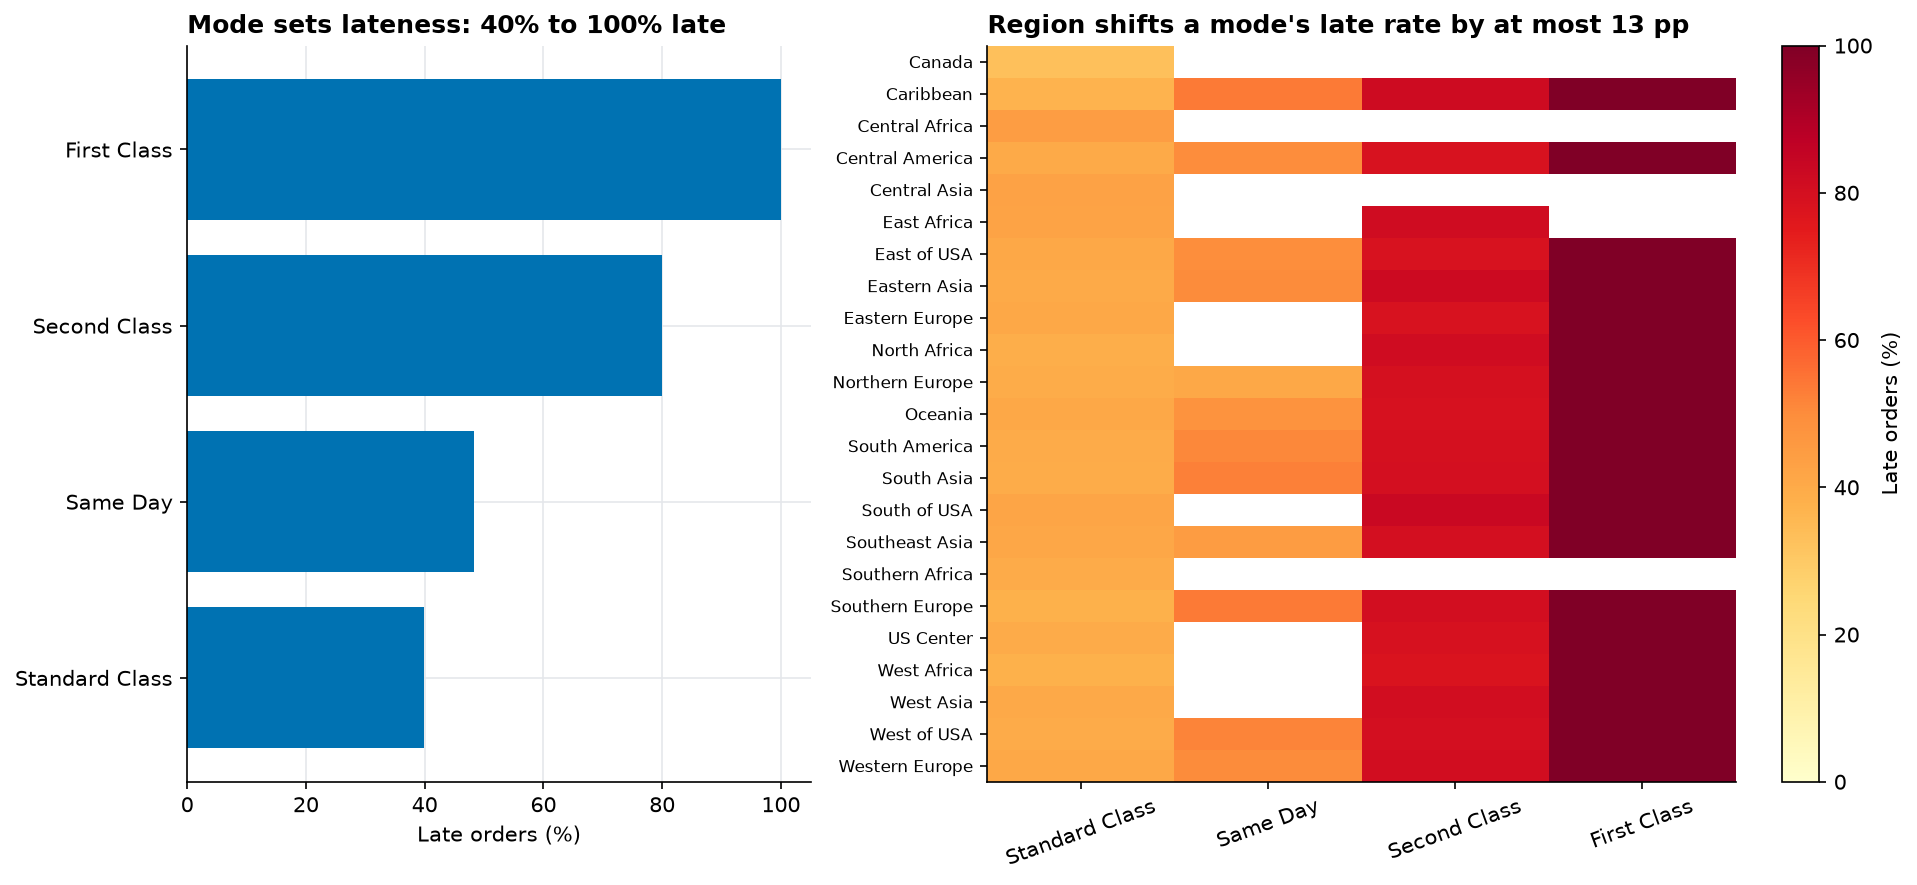

- 57.3% of 62,897 valid orders ship late.
- First Class: 100.0% late (scheduled 1 day(s))
- Second Class: 80.0% late (scheduled 2 day(s))
- Same Day: 48.4% late (scheduled 0 day(s))
- Standard Class: 39.8% late (scheduled 4 day(s))
- Across regions, overall late rate runs only from 52.6% to 60.0%; within a mode the largest region gap is 12.8 pp (cells with at least 100 orders).

**So what:** First Class (scheduled 1 day(s)) is late 100% of the time versus 40% for Standard Class (scheduled 4). Lateness is set mainly by the scheduled-days promise attached to each mode, so review those promises before regional fixes. This analysis does not test the cause.

In [4]:
f = findings[1]
display(Markdown(f"### Finding {f.number}: {f.headline}"))
display(Image(FIG / f.figure))
display(Markdown(chr(10).join(f"- {e}" for e in f.evidence)))
display(Markdown(f"**So what:** {f.so_what}"))

### Finding 3: Margin is 12.0% overall and 37 of 40 categories sit within 2 pp of it

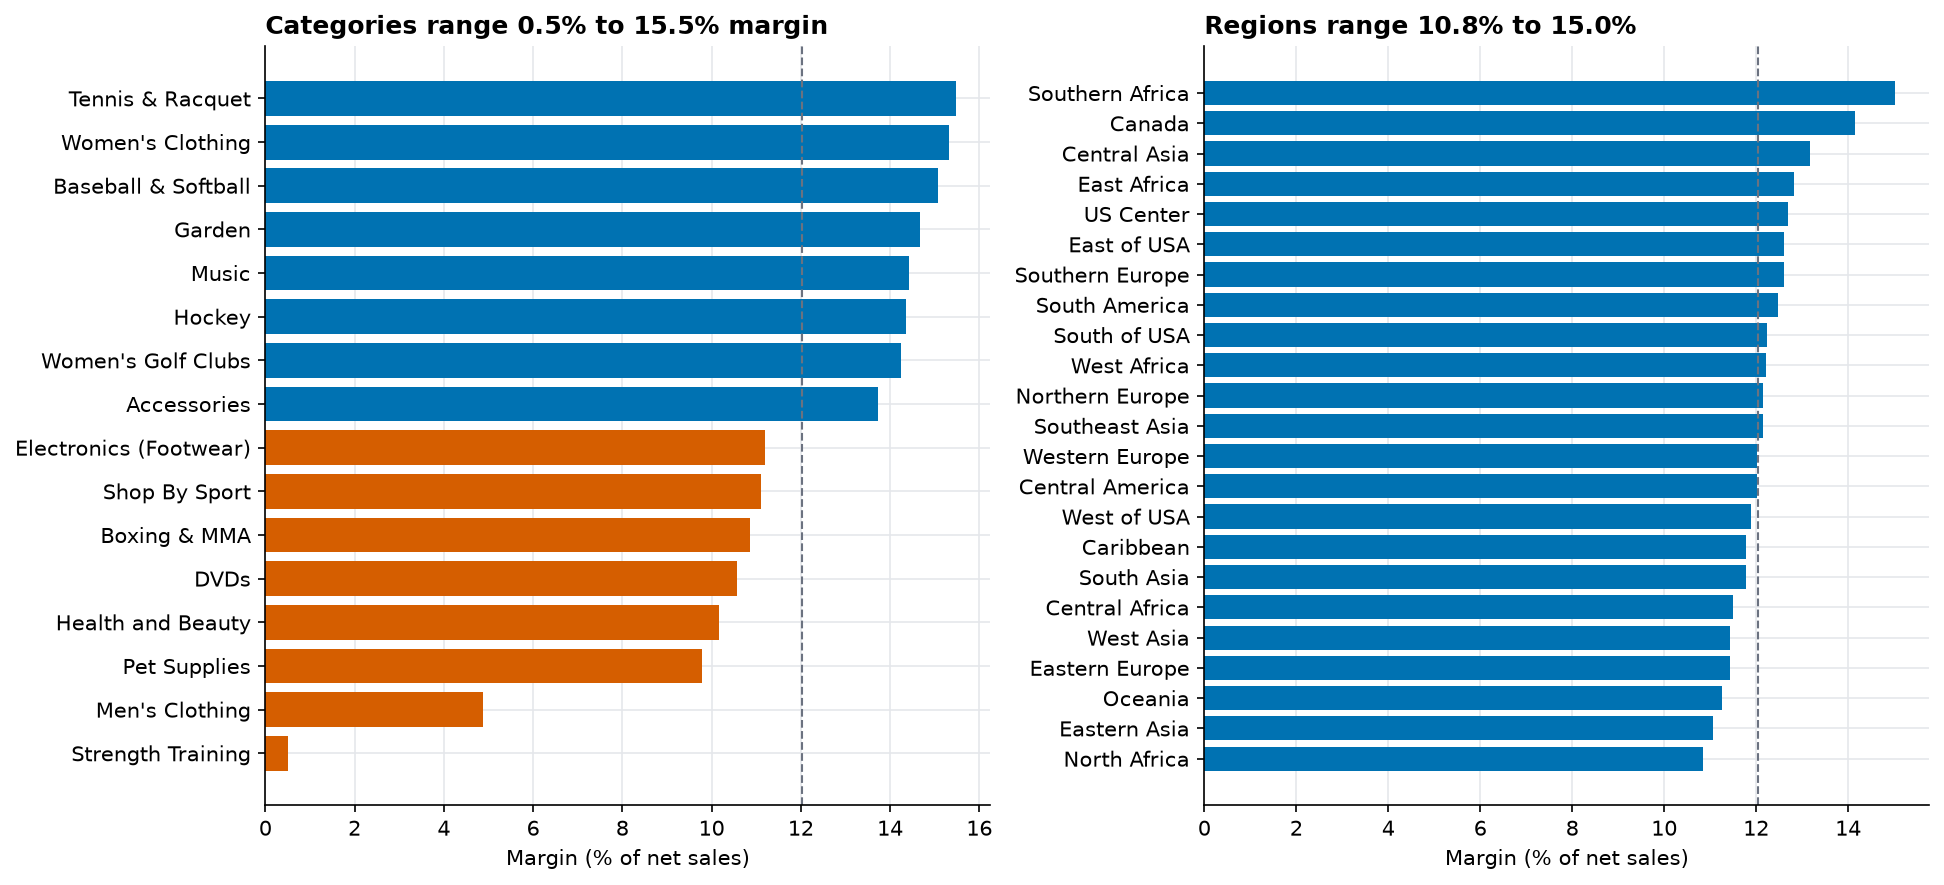

- Overall margin is 12.0% on $31,644,665 net sales ($3,806,421 profit).
- Lowest-margin categories (at least 0.1% of sales): Strength Training 0.5% on $48,457; Men's Clothing 4.9% on $37,456; Pet Supplies 9.8% on $35,835.
- Highest: Tennis & Racquet 15.5%; 37 of 40 categories sit within 2 pp of the overall margin; the three lowest are 0.38% of net sales.
- Regions: lowest North Africa 10.8%, highest Southern Africa 15.0%.

**So what:** The three lowest-margin categories (Strength Training, Men's Clothing, Pet Supplies) are only 0.4% of net sales, so fixing them would barely move total margin. Category and region are not where margin is won or lost; see finding 5 for where profit is actually lost.

In [5]:
f = findings[2]
display(Markdown(f"### Finding {f.number}: {f.headline}"))
display(Image(FIG / f.figure))
display(Markdown(chr(10).join(f"- {e}" for e in f.evidence)))
display(Markdown(f"**So what:** {f.so_what}"))

### Finding 4: Discount depth shows no measurable link to margin % (-0.010 pp per +1 pp, p = 0.54)

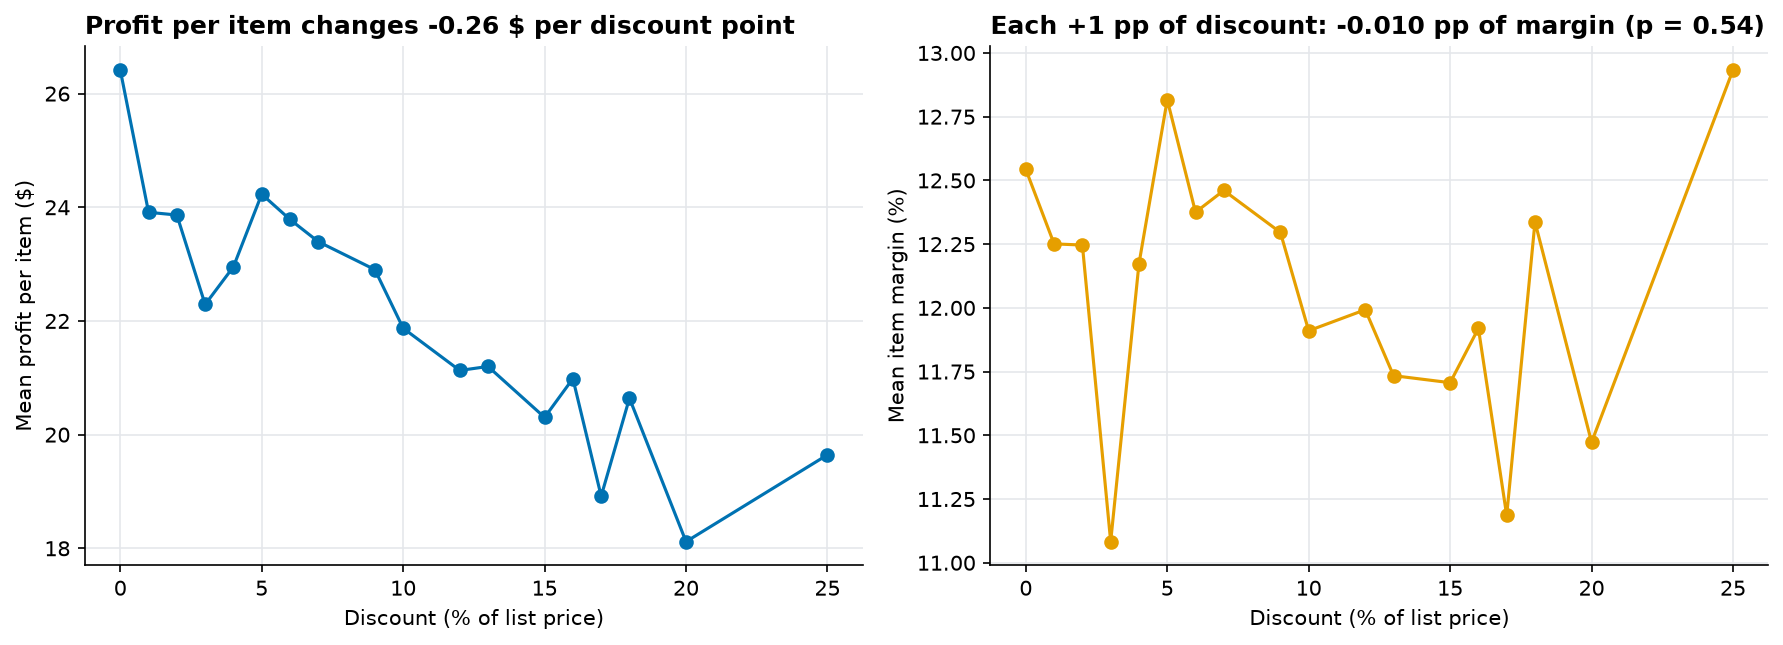

- Holding category, region and shipping mode fixed, each +1 percentage point of discount is associated with a margin that is 0.010 pp lower (95% CI -0.041 to +0.021 pp; not distinguishable from zero, p = 0.535). This is an association in observational data, not a causal effect.
- Model: 172,765 valid items, R-squared 0.000; mean profit per item moves from $26.42 at 0% discount to $19.64 at 25%.
- Robust (HC3) standard errors are 0.99x the classical ones for the discount term; Breusch-Pagan p = 0.8; residual excess kurtosis 10.2.
- Category effects span 13.5 pp; shipping-mode effects at most 0.7 pp.
- R-squared is 0.000: category, region, shipping mode and discount together explain almost none of the item-to-item variation in margin, so item margin is driven by something not in this dataset.

**So what:** In this data, margin % does not move with discount depth, while mean profit per item does fall ($26.42 to $19.64); judge discounts on profit per item rather than margin %. These are associations in observational data, not proof that changing discounts would change profit.

In [6]:
f = findings[3]
display(Markdown(f"### Finding {f.number}: {f.headline}"))
display(Image(FIG / f.figure))
display(Markdown(chr(10).join(f"- {e}" for e in f.evidence)))
display(Markdown(f"**So what:** {f.so_what}"))

### Finding 5: 19% of items lose money, wiping out 49% of gross profit; 10 products cause 90% of the loss

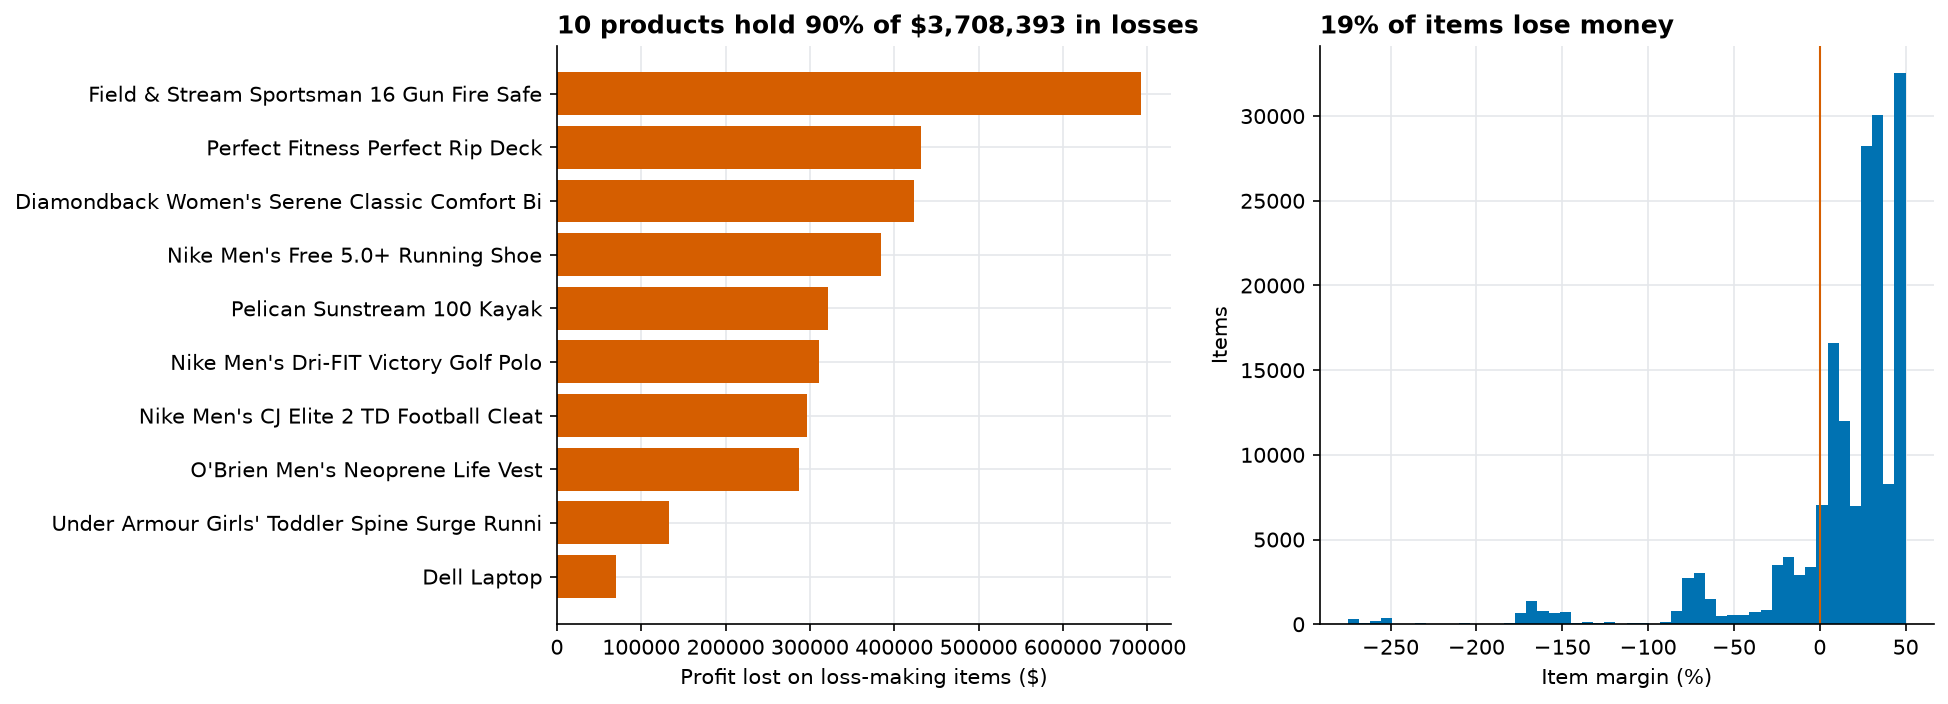

- 32,295 of 172,765 valid items (18.7%) have negative profit, losing $3,708,393 against $7,514,814 earned on profitable items (losses erase 49% of gross profit).
- Largest loss pools: Fishing $693,197; Cleats $432,902; Camping & Hiking $423,599.
- Highest share of loss-making items: Men's Clothing (24.2%), lowest: Golf Bags & Carts (9.8%).
- The 10 worst products hold 90% of all losses (Field & Stream Sportsman 16 Gun Fire Safe: $693,197).

**So what:** Losses are concentrated in a few products, so a product-level price and cost review is the most direct lever.

In [7]:
f = findings[4]
display(Markdown(f"### Finding {f.number}: {f.headline}"))
display(Image(FIG / f.figure))
display(Markdown(chr(10).join(f"- {e}" for e in f.evidence)))
display(Markdown(f"**So what:** {f.so_what}"))

### Finding 6: All 7,754 cancelled or fraud-flagged items are TRANSFER payments

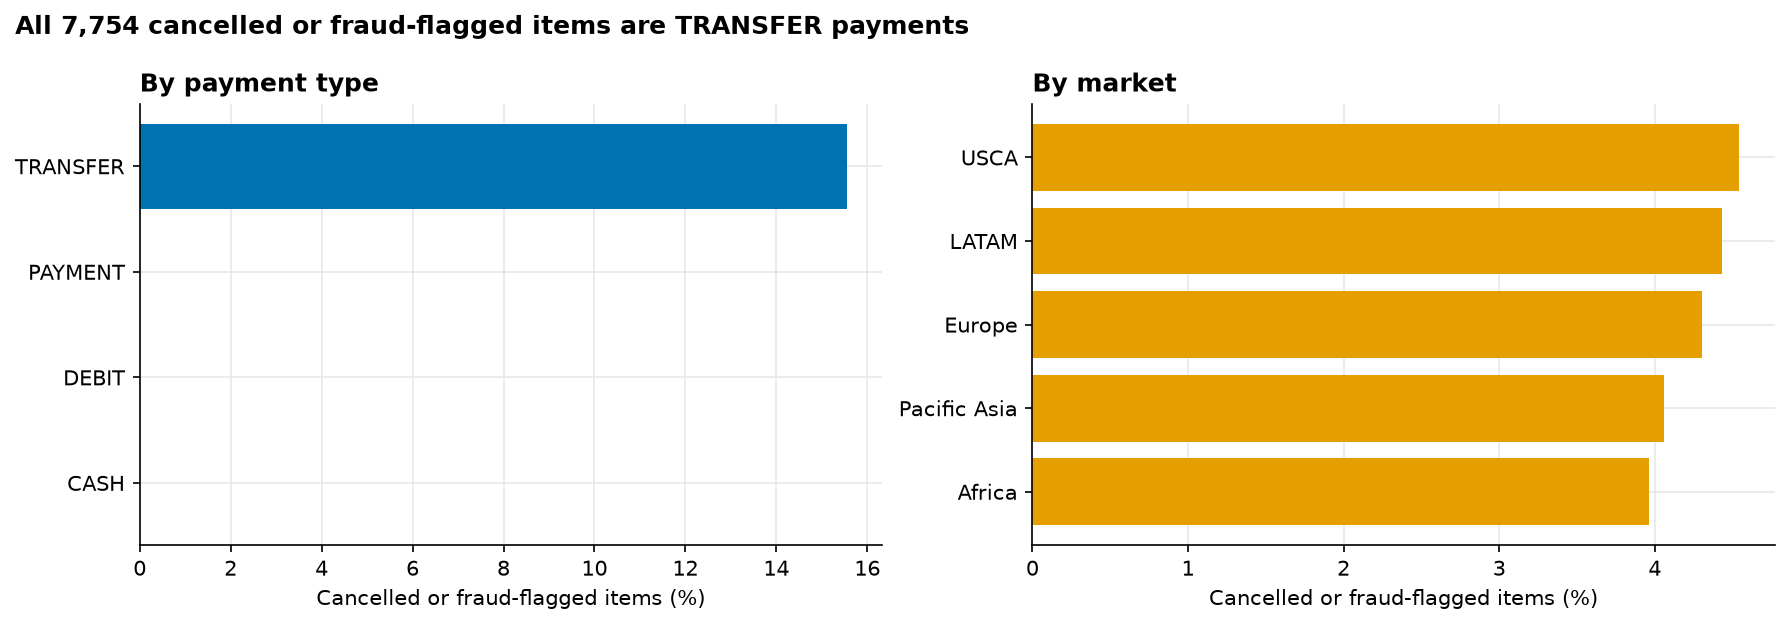

- 7,754 of 180,519 items (4.3%) are cancelled or suspected fraud: CANCELED 3,692, SUSPECTED_FRAUD 4,062.
- Share of items excluded by payment type: TRANSFER 15.5%, PAYMENT 0.0%, DEBIT 0.0%, CASH 0.0%.
- By market the share only ranges from 4.0% to 4.5%.

**So what:** Demand, delivery and margin analyses exclude these items. Of payment type and market, only payment type separates them, so any fraud-screening effort should start there.

In [8]:
f = findings[5]
display(Markdown(f"### Finding {f.number}: {f.headline}"))
display(Image(FIG / f.figure))
display(Markdown(chr(10).join(f"- {e}" for e in f.evidence)))
display(Markdown(f"**So what:** {f.so_what}"))

## Regression: item margin on discount

OLS with HC3 robust standard errors, controlling for category, region and shipping mode. Associational, not causal.

Holding category, region and shipping mode fixed, each +1 percentage point of discount is associated with a margin that is 0.010 pp lower (95% CI -0.041 to +0.021 pp; not distinguishable from zero, p = 0.535). This is an association in observational data, not a causal effect.
n = 172,765   R-squared = 0.000   Breusch-Pagan p = 0.8


,effect_pp,ci_low,ci_high,p
Same Day,-0.276,-1.276,0.725,0.589
Second Class,-0.154,-0.732,0.424,0.603
First Class,0.689,0.069,1.308,0.029


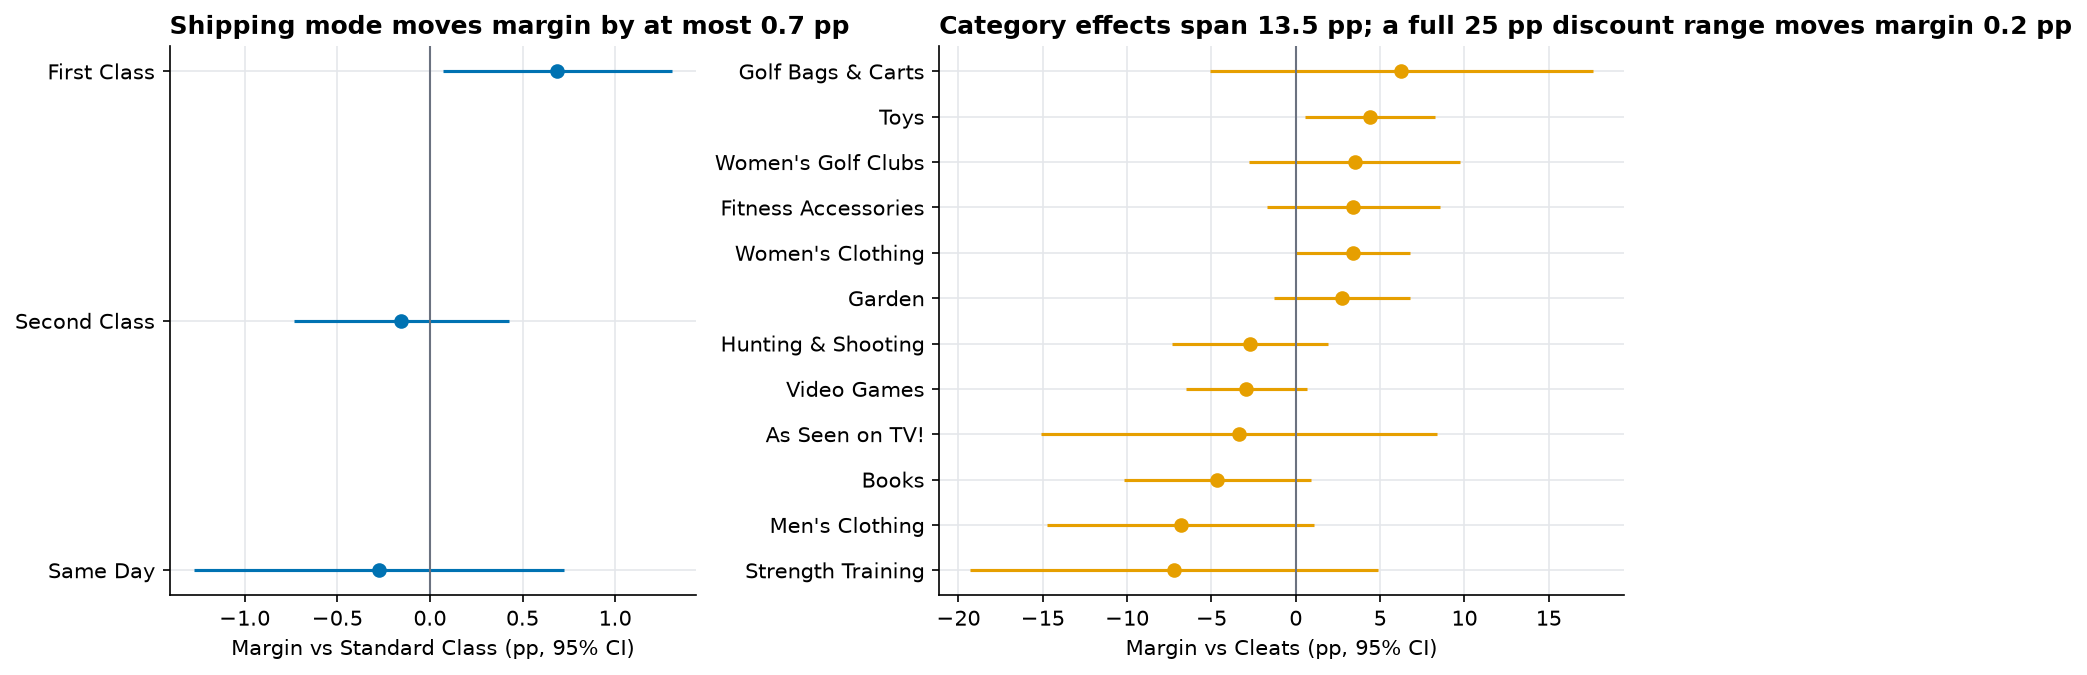

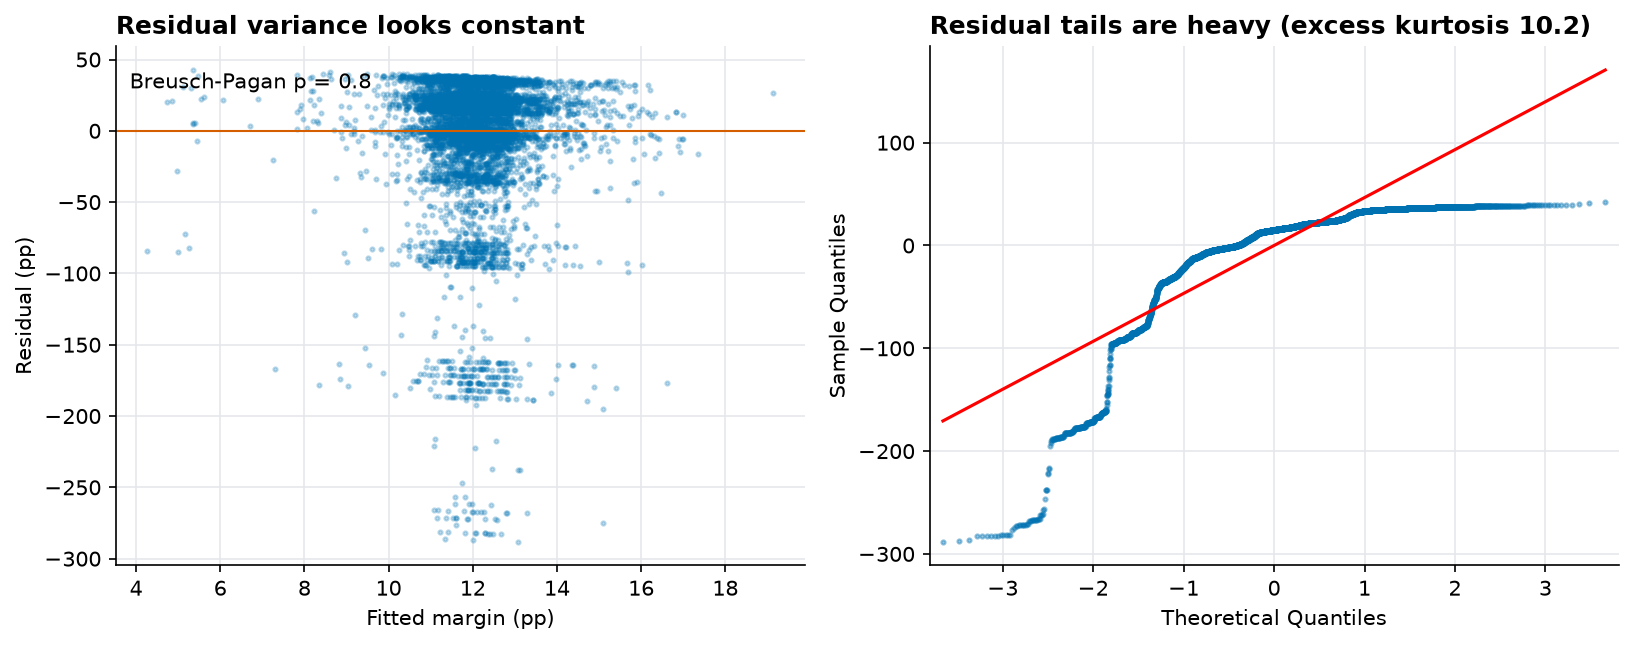

In [9]:
from sca import profitability as prof

print(prof.interpret(model))
print(f"n = {model.n:,}   R-squared = {model.r2:.3f}   Breusch-Pagan p = {model.bp_pvalue:.2g}")
display(model.ship_effects.round(3))
display(Image(FIG / "eda_reg_effects.png"))
display(Image(FIG / "eda_reg_diagnostics.png"))